# K-medoids (AMPL)

In [12]:
import pandas as pd
from sklearn.datasets import load_iris
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

## Data

In [13]:
k = 3
iris = load_iris()
X_raw = iris.data
y = iris.target
X = (X_raw - X_raw.mean(axis=0)) / X_raw.std(axis=0, ddof=1)

## K-medoids

In [14]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

### Labels and medoids from AMPL

In [15]:
df_labels = pd.read_csv("iris_labels.txt", header=None)
ampl_labels = df_labels.iloc[:, 0].values

df_medoids = pd.read_csv("iris_medoids.txt", header=None)
ampl_medoids = df_medoids.iloc[:, 0].values - 1

X_medoids_pca = X_pca[ampl_medoids]

### Visualisation

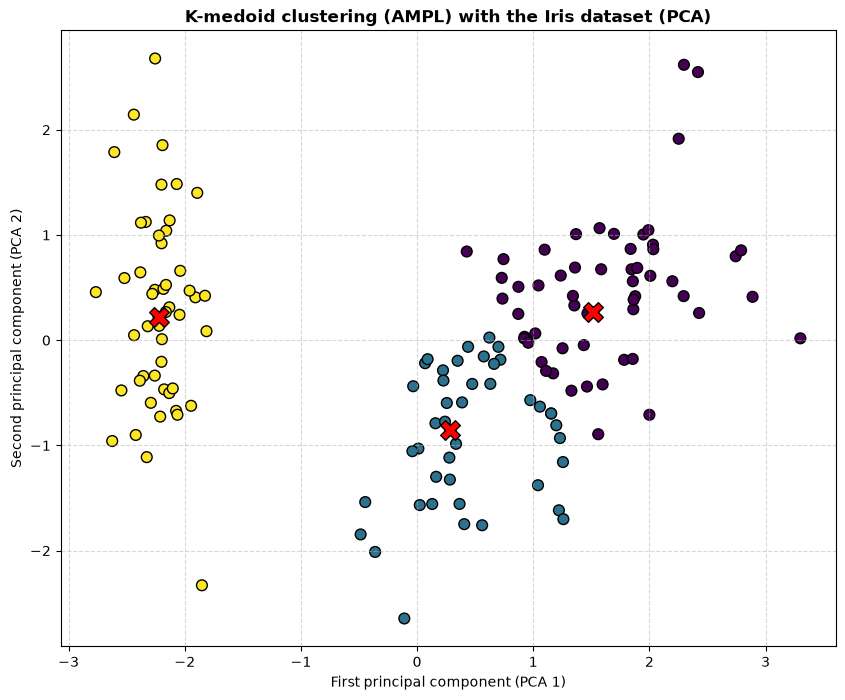

In [16]:
plt.figure(figsize=(10, 8))
scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=ampl_labels,
    cmap='viridis_r',
    edgecolor='k',
    s=60,
    alpha=1,
)
plt.scatter(
    X_medoids_pca[:, 0],
    X_medoids_pca[:, 1],
    c='red',
    marker='X',
    s=200,
    edgecolor='black',
    label='Medoids',
    zorder=3,
)
plt.title(
    'K-medoid clustering (AMPL) with the Iris dataset (PCA)',
    fontsize=12,
    fontweight='bold',
)
plt.xlabel('First principal component (PCA 1)')
plt.ylabel('Second principal component (PCA 2)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.savefig("iris_kmedoids_ampl.png", dpi=300, bbox_inches="tight")
plt.show()